=== Model Comparison ===
                        Model  Accuracy  Precision   Recall  F1-Score
                  CART (Gini)  0.912281   0.955882 0.902778  0.928571
       C4.5 Variant (Entropy)  0.912281   0.969697 0.888889  0.927536
Ensemble Tree (Random Forest)  0.956140   0.958904 0.972222  0.965517

Best Performing Model: Ensemble Tree (Random Forest)

--- Classification Report (Ensemble Tree (Random Forest)) ---
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



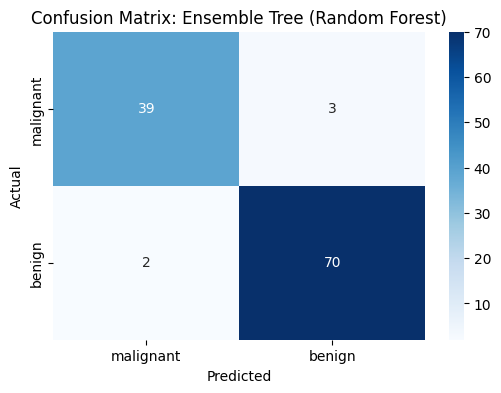

In [1]:
# ==========================================
# 1. Imports & Dataset Loading
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ==========================================
# 2. Define the 3 Models
# ==========================================
models = {
    "CART (Gini)": DecisionTreeClassifier(criterion='gini', random_state=42),
    "C4.5 Variant (Entropy)": DecisionTreeClassifier(criterion='entropy', random_state=42),
    "Ensemble Tree (Random Forest)": RandomForestClassifier(n_estimators=100, random_state=42)
}

# ==========================================
# 3. Train, Evaluate, and Compare
# ==========================================
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

comparison_df = pd.DataFrame(results)
print("=== Model Comparison ===")
print(comparison_df.to_string(index=False))

# Best Model Selection based on F1-Score
best_model_name = comparison_df.sort_values(by="F1-Score", ascending=False).iloc[0]["Model"]
print(f"\nBest Performing Model: {best_model_name}")

# ==========================================
# 4. Detailed Evaluation for Best Model
# ==========================================
best_model = models[best_model_name]
best_pred = best_model.predict(X_test)

print(f"\n--- Classification Report ({best_model_name}) ---")
print(classification_report(y_test, best_pred, target_names=data.target_names))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names, yticklabels=data.target_names)
plt.title(f'Confusion Matrix: {best_model_name}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()